# M2: Resume-Job Matching Baseline Reproduction

This notebook reproduces the baseline methods from our selected research paper:

**Calibrated Resume-Job Matching for Trustworthy LLM-Assisted Recruiter Screening**

The system compares a resume with a job description and predicts one of these classes:

- Good Fit
- Potential Fit
- No Fit

## M2 Objectives

1. Load and study the dataset.
2. Check missing values, labels, and duplicate records.
3. Clean and prepare the text.
4. Reproduce TF-IDF with cosine similarity.
5. Reproduce paired TF-IDF with an SGD classifier.
6. Compare our results with the paper results.

## Main Metric

We use macro-F1 as the main metric because it gives equal importance to all three classes.

## Setup

- Platform: Google Colab
- Runtime: CPU
- Random seed: 42

In [1]:
%pip install -q datasets

import sys
import time
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import datasets

from datasets import load_dataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
NOTEBOOK_START_TIME = time.time()

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)
sns.set_theme(style="whitegrid")

print("Setup complete")
print(f"Python: {sys.version.split()[0]}")
print(f"datasets: {datasets.__version__}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")
print(f"Matplotlib: {matplotlib.__version__}")
print(f"Seaborn: {sns.__version__}")
print(f"Random seed: {SEED}")

Setup complete
Python: 3.13.16
datasets: 4.8.5
pandas: 2.2.3
NumPy: 2.1.3
scikit-learn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Random seed: 42


In [2]:
DATASET_NAME = "cnamuangtoun/resume-job-description-fit"

dataset = load_dataset(DATASET_NAME)

print(f"Dataset: {DATASET_NAME}")
print(dataset)

for split_name, split_data in dataset.items():
    print(f"{split_name}: {len(split_data):,} rows")

train.csv: reconstructing file:   0%|          |  0.00B / 53.4MB            

train.csv: downloading bytes:           |  0.00B            

test.csv: reconstructing file:   0%|          |  0.00B / 15.2MB            

test.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/6241 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1759 [00:00<?, ? examples/s]

Dataset: cnamuangtoun/resume-job-description-fit
DatasetDict({
    train: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 6241
    })
    test: Dataset({
        features: ['resume_text', 'job_description_text', 'label'],
        num_rows: 1759
    })
})
train: 6,241 rows
test: 1,759 rows


In [3]:
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)
print("\nColumns:", train_df.columns.tolist())
print("\nData types:")
print(train_df.dtypes)

print("\nTraining sample:")
display(train_df.head(3))

Training shape: (6241, 3)
Test shape: (1759, 3)

Columns: ['resume_text', 'job_description_text', 'label']

Data types:
resume_text             object
job_description_text    object
label                   object
dtype: object

Training sample:


,resume_text,job_description_text,label
0,SummaryHighly motivated Sales Associate with extensive customer service and sales experience. Outgoing sales profess...,Net2Source Inc. is an award-winning total workforce solutions company recognized by Staffing Industry Analysts for o...,No Fit
1,Professional SummaryCurrently working with Caterpillar as an contract employee Active in several NPI and CPI project...,At Salas OBrien we tell our clients that were engineered for impact. This passion for making a difference applies ju...,No Fit
2,"SummaryI started my construction career in June of 2017 in Jacksonville, Florida as an Electrical Apprentice working...",Schweitzer Engineering Laboratories (SEL) Infrastructure Defense Division seeks a talented individual for a cybersec...,No Fit


In [4]:
label_order = ["Good Fit", "Potential Fit", "No Fit"]

all_labels = sorted(
    set(train_df["label"].dropna()) | set(test_df["label"].dropna())
)

print("Labels found:", all_labels)

label_counts = pd.DataFrame({
    "Train": train_df["label"].value_counts(),
    "Test": test_df["label"].value_counts()
}).reindex(label_order).fillna(0).astype(int)

label_counts["Total"] = label_counts["Train"] + label_counts["Test"]
label_counts["Total (%)"] = (
    label_counts["Total"] / label_counts["Total"].sum() * 100
).round(2)

display(label_counts)

Labels found: ['Good Fit', 'No Fit', 'Potential Fit']


,Train,Test,Total,Total (%)
label,,,,
Good Fit,1542,458,2000,25.0
Potential Fit,1556,444,2000,25.0
No Fit,3143,857,4000,50.0


In [5]:
def missing_value_summary(dataframe):
    missing = dataframe.isna().sum()
    empty = dataframe.apply(
        lambda column: column.dropna().astype(str).str.strip().eq("").sum()
    )

    return pd.DataFrame({
        "Missing values": missing,
        "Empty values": empty,
        "Total affected": missing + empty
    })

missing_summary = pd.concat(
    {
        "Train": missing_value_summary(train_df),
        "Test": missing_value_summary(test_df)
    },
    names=["Split", "Column"]
)

display(missing_summary)

Missing values  Empty values  Total affected
Split Column                                                            
Train resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0
Test  resume_text                        0             0               0
      job_description_text               0             0               0
      label                              0             0               0

In [6]:
PAIR_COLUMNS = ["resume_text", "job_description_text"]

def find_duplicate_pairs(dataframe):
    groups = (
        dataframe.groupby(PAIR_COLUMNS, dropna=False)
        .agg(
            row_count=("label", "size"),
            unique_labels=("label", "nunique"),
            labels=("label", lambda values: sorted(values.unique()))
        )
        .reset_index()
    )
    return groups[groups["row_count"] > 1].copy()

train_duplicate_groups = find_duplicate_pairs(train_df)
test_duplicate_groups = find_duplicate_pairs(test_df)

duplicate_summary = pd.DataFrame({
    "Train": [
        len(train_duplicate_groups),
        train_duplicate_groups["row_count"].sum(),
        (train_duplicate_groups["unique_labels"] > 1).sum(),
        (train_duplicate_groups["unique_labels"] == 1).sum()
    ],
    "Test": [
        len(test_duplicate_groups),
        test_duplicate_groups["row_count"].sum(),
        (test_duplicate_groups["unique_labels"] > 1).sum(),
        (test_duplicate_groups["unique_labels"] == 1).sum()
    ]
}, index=[
    "Duplicate groups",
    "Rows in duplicate groups",
    "Conflicting-label groups",
    "Same-label groups"
])

display(duplicate_summary)

print("\nTraining duplicate-group details:")
display(
    train_duplicate_groups[
        ["row_count", "unique_labels", "labels"]
    ].reset_index(drop=True)
)

,Train,Test
Duplicate groups,7,0
Rows in duplicate groups,14,0
Conflicting-label groups,6,0
Same-label groups,1,0



Training duplicate-group details:


,row_count,unique_labels,labels
0,2,2,"[No Fit, Potential Fit]"
1,2,2,"[Good Fit, No Fit]"
2,2,2,"[Good Fit, No Fit]"
3,2,2,"[Good Fit, No Fit]"
4,2,2,"[No Fit, Potential Fit]"
5,2,1,[No Fit]
6,2,2,"[Good Fit, No Fit]"


In [7]:
def calculate_overlap(train_values, test_values):
    train_values = list(train_values)
    test_values = list(test_values)

    train_set = set(train_values)
    test_set = set(test_values)
    shared_values = train_set & test_set
    test_overlap_count = sum(value in train_set for value in test_values)

    return {
        "Train unique": len(train_set),
        "Test unique": len(test_set),
        "Shared unique": len(shared_values),
        "Test rows with overlap": test_overlap_count,
        "Test overlap (%)": round(test_overlap_count / len(test_values) * 100, 2)
    }

train_pairs = list(zip(train_df["resume_text"], train_df["job_description_text"]))
test_pairs = list(zip(test_df["resume_text"], test_df["job_description_text"]))

overlap_summary = pd.DataFrame({
    "Resume text": calculate_overlap(
        train_df["resume_text"], test_df["resume_text"]
    ),
    "Job description": calculate_overlap(
        train_df["job_description_text"], test_df["job_description_text"]
    ),
    "Resume-job pair": calculate_overlap(train_pairs, test_pairs)
}).T

display(overlap_summary)

,Train unique,Test unique,Shared unique,Test rows with overlap,Test overlap (%)
Resume text,642.0,477.0,476.0,1758.0,99.94
Job description,280.0,71.0,0.0,0.0,0.00
Resume-job pair,6234.0,1759.0,0.0,0.0,0.00


In [8]:
analysis_df = pd.concat(
    [
        train_df.assign(split="Train"),
        test_df.assign(split="Test")
    ],
    ignore_index=True
)

analysis_df["resume_words"] = (
    analysis_df["resume_text"].astype(str).str.split().str.len()
)
analysis_df["job_words"] = (
    analysis_df["job_description_text"].astype(str).str.split().str.len()
)
analysis_df["resume_characters"] = (
    analysis_df["resume_text"].astype(str).str.len()
)
analysis_df["job_characters"] = (
    analysis_df["job_description_text"].astype(str).str.len()
)

length_summary = analysis_df.groupby("split").agg(
    resume_words_mean=("resume_words", "mean"),
    resume_words_median=("resume_words", "median"),
    resume_words_max=("resume_words", "max"),
    job_words_mean=("job_words", "mean"),
    job_words_median=("job_words", "median"),
    job_words_max=("job_words", "max"),
    resume_characters_mean=("resume_characters", "mean"),
    job_characters_mean=("job_characters", "mean")
).round(1)

display(length_summary)

,resume_words_mean,resume_words_median,resume_words_max,job_words_mean,job_words_median,job_words_max,resume_characters_mean,job_characters_mean
split,,,,,,,,
Test,691.4,618.0,2738,402.9,308.0,1254,5663.3,2939.2
Train,708.1,618.0,3134,371.5,328.0,1079,5804.4,2731.3


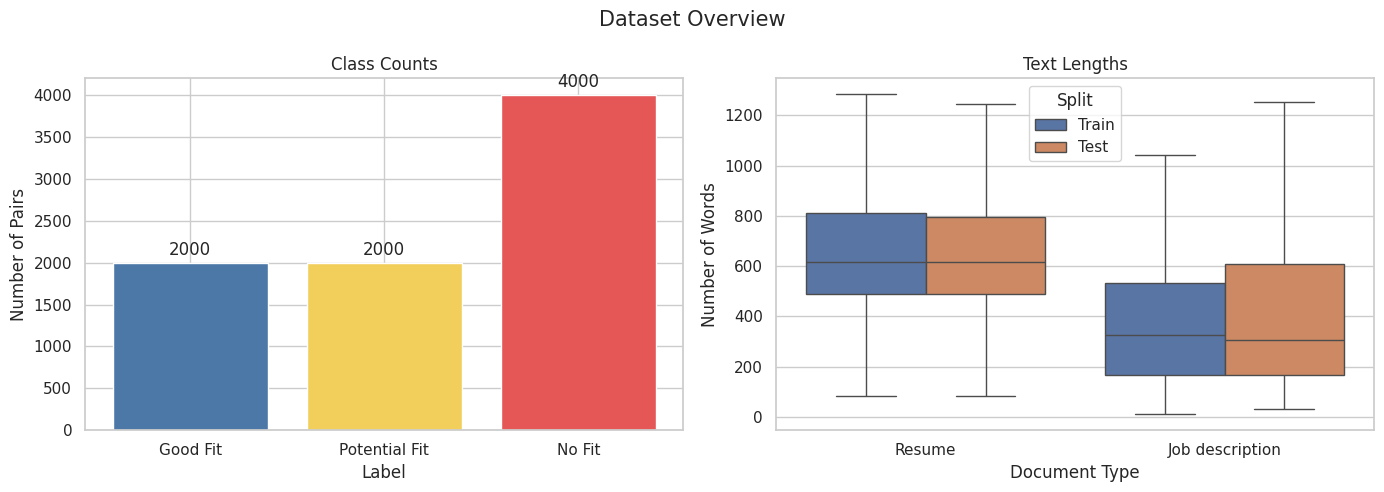

Figure saved to: m2/figures/dataset-overview.png


In [9]:
from pathlib import Path

FIGURE_DIR = Path("m2/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

total_label_counts = (
    analysis_df["label"]
    .value_counts()
    .reindex(label_order)
)

length_plot_df = analysis_df[
    ["split", "resume_words", "job_words"]
].melt(
    id_vars="split",
    var_name="document_type",
    value_name="word_count"
)

length_plot_df["document_type"] = length_plot_df["document_type"].replace({
    "resume_words": "Resume",
    "job_words": "Job description"
})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

bars = axes[0].bar(
    total_label_counts.index,
    total_label_counts.values,
    color=["#4C78A8", "#F2CF5B", "#E45756"]
)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Class Counts")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Number of Pairs")

sns.boxplot(
    data=length_plot_df,
    x="document_type",
    y="word_count",
    hue="split",
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Text Lengths")
axes[1].set_xlabel("Document Type")
axes[1].set_ylabel("Number of Words")
axes[1].legend(title="Split")

fig.suptitle("Dataset Overview", fontsize=15)
plt.tight_layout()

figure_path = FIGURE_DIR / "dataset-overview.png"
fig.savefig(figure_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"Figure saved to: {figure_path}")

In [10]:
dataset_info = dataset["train"].info
DATASET_URL = f"https://huggingface.co/datasets/{DATASET_NAME}"

def show_metadata(value):
    if value is None or str(value).strip() == "":
        return "Not provided"
    return str(value).strip()

dataset_metadata = pd.DataFrame({
    "Value": [
        DATASET_NAME,
        DATASET_URL,
        show_metadata(dataset_info.description),
        show_metadata(dataset_info.license),
        show_metadata(dataset_info.homepage),
        show_metadata(dataset_info.citation)
    ]
}, index=[
    "Dataset name",
    "Dataset page",
    "Description",
    "Licence",
    "Homepage",
    "Citation"
])

display(dataset_metadata)

,Value
Dataset name,cnamuangtoun/resume-job-description-fit
Dataset page,https://huggingface.co/datasets/cnamuangtoun/resume-job-description-fit
Description,Not provided
Licence,Not provided
Homepage,Not provided
Citation,Not provided


## Dataset Audit Findings

The `resume-job-description-fit` dataset is publicly available on Hugging Face. It contains resume-job pairs labelled as Good Fit, Potential Fit, or No Fit.

### Dataset Structure

| Split | Rows |
|---|---:|
| Training | 6,241 |
| Test | 1,759 |
| Total | 8,000 |

The dataset contains three columns:

- `resume_text`
- `job_description_text`
- `label`

### Label Distribution

| Label | Total rows | Percentage |
|---|---:|---:|
| Good Fit | 2,000 | 25% |
| Potential Fit | 2,000 | 25% |
| No Fit | 4,000 | 50% |

The No Fit class contains half of the dataset. Macro-F1 is therefore used as the main metric so that every class receives equal importance.

### Data Quality

- No missing values were found.
- No empty text or label values were found.
- The training split contains seven duplicate resume-job groups.
- Six duplicate groups contain conflicting labels.
- One duplicate group contains the same label.
- The test split contains no duplicate resume-job pairs.

These results match the duplicate information reported in the anchor paper.

### Split Overlap

- 476 unique resumes appear in both training and test data.
- 1,758 of the 1,759 test rows use a resume that also appears in training.
- No job descriptions are shared between training and test.
- No complete resume-job pairs are shared between training and test.

There is no exact pair overlap. However, the high resume overlap means that the test split mainly checks known resumes against new job descriptions.

### Dataset Information Limitations

The Hugging Face dataset page does not provide:

- A detailed dataset description
- Licence information
- An official homepage
- A recommended citation
- Clear information about how the data was collected

The dataset is suitable for research experiments, but these missing details should be considered when interpreting the results. It should not be used to make real hiring decisions.

In [11]:
audit_checks = {
    "Training rows equal 6,241": len(train_df) == 6241,
    "Test rows equal 1,759": len(test_df) == 1759,
    "Expected columns are present": train_df.columns.tolist() == [
        "resume_text", "job_description_text", "label"
    ],
    "Expected labels are present": set(all_labels) == {
        "Good Fit", "Potential Fit", "No Fit"
    },
    "No missing or empty values": (
        missing_summary["Total affected"].sum() == 0
    ),
    "Seven training duplicate groups": len(train_duplicate_groups) == 7,
    "Six conflicting duplicate groups": (
        train_duplicate_groups["unique_labels"].gt(1).sum() == 6
    ),
    "One same-label duplicate group": (
        train_duplicate_groups["unique_labels"].eq(1).sum() == 1
    ),
    "No test duplicate groups": len(test_duplicate_groups) == 0
}

audit_results = pd.DataFrame({
    "Check": audit_checks.keys(),
    "Passed": audit_checks.values()
})

display(audit_results)

if audit_results["Passed"].all():
    print("All dataset audit checks passed.")
else:
    print("Some dataset audit checks failed. Review the results above.")

,Check,Passed
0,"Training rows equal 6,241",True
1,"Test rows equal 1,759",True
2,Expected columns are present,True
3,Expected labels are present,True
4,No missing or empty values,True
5,Seven training duplicate groups,True
6,Six conflicting duplicate groups,True
7,One same-label duplicate group,True
8,No test duplicate groups,True


All dataset audit checks passed.
